In [1]:
from __future__ import print_function
import os
import cv2 
import numpy as np
import pandas as pd   
import matplotlib.pyplot as plt
from PIL import Image
from pillow_heif import register_heif_opener
import random
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.model_selection import KFold, cross_val_score, cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold
from skimage.feature import local_binary_pattern
import warnings
warnings.filterwarnings("ignore")

In [2]:
GROUP = "C5"
DTYPE="LBP"
DIR_TRAIN = "DATA/TRAINING/"
GROUP_path = DIR_TRAIN+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path = os.listdir(GROUP_path)
resume = []
data_path = []
for HH in HH_path:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT = pd.DataFrame(resume)    # values
pdDT.columns = ["Humidity", "numberImages", "pathImages"]
pdDT

,Humidity,numberImages,pathImages
0,C5_10,28,"[DATA/TRAINING/C5/C5_10/IMG_7706.HEIC, DATA/TR..."
1,C5_11,30,"[DATA/TRAINING/C5/C5_11/IMG_7780.HEIC, DATA/TR..."
2,C5_12,26,"[DATA/TRAINING/C5/C5_12/IMG_7858.HEIC, DATA/TR..."
3,C5_13,27,"[DATA/TRAINING/C5/C5_13/IMG_7917.HEIC, DATA/TR..."
4,C5_14,27,"[DATA/TRAINING/C5/C5_14/IMG_7981.HEIC, DATA/TR..."
5,C5_15,28,"[DATA/TRAINING/C5/C5_15/IMG_8046.jpg, DATA/TRA..."
6,C5_16,25,"[DATA/TRAINING/C5/C5_16/IMG_8109.HEIC, DATA/TR..."


In [3]:
def read_imgHEIC(pic_path):
    register_heif_opener(); im = Image.open(pic_path)
    return cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR)

In [4]:
def flip_image_vertical(image):
    height, width, channels = image.shape
    if(height < width):
        image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
    return image

In [5]:
def resize_image(img, scale_percent = 10):
     # percent of original size
    width = int(img.shape[1] * scale_percent / 100)
    height = int(img.shape[0] * scale_percent / 100)
    dim = (width, height)
    #print(dim)
    # resize image
    resized = cv2.resize(img, dim, interpolation = cv2.INTER_AREA)
    return resized

In [6]:
def read_image(pic_path):
    ext = pic_path.split(".")[1]
    if ext=="HEIC":
        return read_imgHEIC(pic_path)
    else:
        img=cv2.imread(pic_path)
        return img

Text(0.5, 1.0, '16% IMG_8145.HEIC')

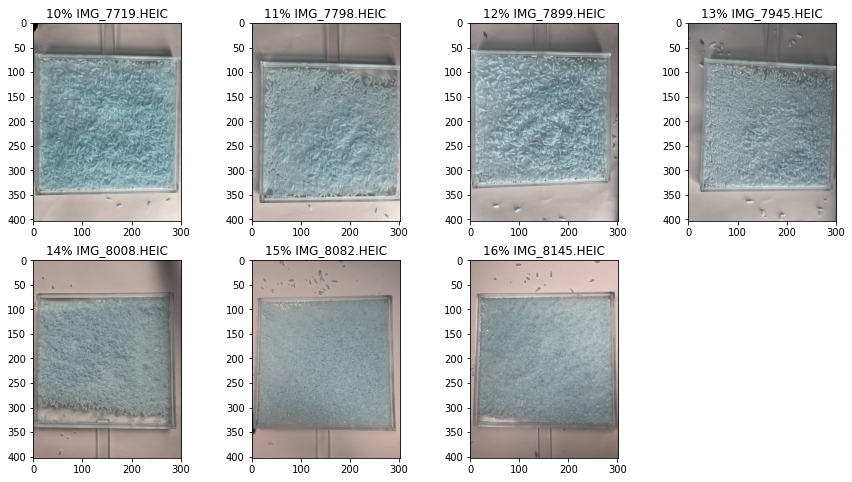

In [7]:
fig=plt.figure(figsize=(15, 8)) 
ax1 = fig.add_subplot(2,4,1); path_image= random.randint(0, 25)
image = read_image(data_path[0][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax1.imshow(image); ax1.set_title("10% " + data_path[0][path_image].split("/")[4])
ax2 = fig.add_subplot(2,4,2); path_image= random.randint(0, 25)
image = read_image(data_path[1][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax2.imshow(image); ax2.set_title("11% "+ data_path[1][path_image].split("/")[4])
ax3 = fig.add_subplot(2,4,3); path_image= random.randint(0, 25)
image = read_image(data_path[2][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax3.imshow(image); ax3.set_title("12% "+ data_path[2][path_image].split("/")[4])
ax4 = fig.add_subplot(2,4,4); path_image= random.randint(0, 25)
image = read_image(data_path[3][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax4.imshow(image); ax4.set_title("13% "+ data_path[3][path_image].split("/")[4])
ax5 = fig.add_subplot(2,4,5); path_image= random.randint(0, 25)
image = read_image(data_path[4][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax5.imshow(image); ax5.set_title("14% "+ data_path[4][path_image].split("/")[4])
ax6 = fig.add_subplot(2,4,6); path_image= random.randint(0, 25)
image = read_image(data_path[5][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax6.imshow(image); ax6.set_title("15% "+ data_path[5][path_image].split("/")[4])
ax7 = fig.add_subplot(2,4,7); path_image= random.randint(0, 25)
image = read_image(data_path[6][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax7.imshow(image); ax7.set_title("16% "+ data_path[6][path_image].split("/")[4])

In [154]:
#Parameters
HH = ['10', '11', '12', '13', '14', '15', '16']
#bins=44; #width=2024; height=3032; 
scale=3
dtHH=[]
for lstImgs, H in zip(data_path, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        #print(image.shape)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

        # Uniform LBP is used
        P=16; R=2
        lbp_ = local_binary_pattern(gray, P, R, method='uniform')
        n_bins = int(lbp_.max() + 1)
        hist_, bin_edges = np.histogram(lbp_.ravel(), bins=n_bins, range=(0, n_bins), density=True)
        arr_img_hist.append(hist_)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["P"] = P
    pdGrayFeatures["R"] = R
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH.append(pdGrayFeatures)

In [155]:
result = pd.concat(dtHH)

DIR= "FEATURES/ORIGINAL/GLOBAL/TRAINING/"; 
result.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'_'+str(P)+'_'+str(R)+'bins.csv', index=False)
result.head(10)

,0,1,2,3,4,5,6,7,8,9,...,16,17,scale,P,R,height,width,channels,IMAGENAME,HUMIDITY
0,0.071481,0.055278,0.036759,0.023981,0.014537,0.017870,0.023981,0.044074,0.066389,0.049074,...,0.072593,0.370093,3,16,2,120,90,3,IMG_7706.HEIC,10
1,0.068148,0.059259,0.033148,0.025185,0.017778,0.020370,0.027037,0.043056,0.060278,0.043148,...,0.076852,0.378889,3,16,2,120,90,3,IMG_7709.HEIC,10
2,0.074352,0.061019,0.031667,0.022685,0.013426,0.019630,0.024722,0.040833,0.057407,0.042593,...,0.077685,0.380648,3,16,2,120,90,3,IMG_7710.HEIC,10
3,0.076574,0.061667,0.033056,0.018981,0.016019,0.018333,0.022407,0.031019,0.043981,0.036574,...,0.078426,0.407222,3,16,2,120,90,3,IMG_7713.HEIC,10
4,0.072778,0.063889,0.028426,0.023611,0.016019,0.019259,0.021296,0.032315,0.050648,0.037593,...,0.077870,0.398796,3,16,2,120,90,3,IMG_7714.HEIC,10
5,0.075926,0.059722,0.037037,0.019907,0.015648,0.019815,0.026019,0.032870,0.051296,0.035093,...,0.077130,0.388426,3,16,2,120,90,3,IMG_7718.HEIC,10
6,0.073611,0.063426,0.035185,0.021667,0.014352,0.019167,0.020370,0.031204,0.045000,0.041111,...,0.077222,0.394907,3,16,2,120,90,3,IMG_7719.HEIC,10
7,0.077500,0.058796,0.032685,0.020648,0.015370,0.018981,0.021481,0.034444,0.045185,0.042500,...,0.084444,0.391389,3,16,2,120,90,3,IMG_7721.HEIC,10
8,0.074167,0.058981,0.031852,0.022315,0.017500,0.017593,0.020278,0.030463,0.046759,0.040648,...,0.077222,0.404444,3,16,2,120,90,3,IMG_7723.HEIC,10
9,0.071019,0.058704,0.034537,0.020463,0.016759,0.018056,0.022685,0.030833,0.045093,0.043889,...,0.082222,0.400926,3,16,2,120,90,3,IMG_7725.HEIC,10


# Classification

In [156]:
dtFeatures=result#.drop(['IMAGENAME'], axis=1)
#dtFeatures.head()
X = dtFeatures.values[:, :-8]
#X

In [157]:

# Normalization -> values[0-1]
scaler = MinMaxScaler()
X_scale = scaler.fit_transform(X)     
y = dtFeatures.values[:, -1]
#y

In [158]:
def compute_classification_metrics(y_pred, y_test):
    acc = np.sum(y_pred == y_test) / float(len(y_test))
    precision =np.mean(precision_score(y_test, y_pred, average=None, zero_division=1))
    recall =np.mean(recall_score(y_test, y_pred, average=None, zero_division=1))
    F1 = 2 * (precision * recall) / (precision + recall)
    return acc, precision, recall, F1

In [159]:
def get_CV_CLASSIFICATION_MODELS(model, X, y, rescale=False):
    dt_lg_test=[]  
    if rescale==True:
        y=y-10
        #print(y)
    kfold = StratifiedKFold(n_splits=10, shuffle=True)
    k_fold=1
    for train_index , test_index in kfold.split(X, y):

        X_train , X_test = X[train_index], X[test_index]
        y_train , y_test = y[train_index], y[test_index]
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)  # predict label

        [acc, precision, recall, F1] = compute_classification_metrics(y_pred, y_test)
        dt_lg_test.append([k_fold, acc, precision, recall, F1])
        k_fold=k_fold+1
    return dt_lg_test

#### Random Forest Classifier

In [160]:
modelRFC=RandomForestClassifier(n_estimators=1000) 
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelRFC, X_scale, y)
modelName="RF_C"

In [161]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["P"]=P; dtFoldTrain["R"]=R; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'_'+str(P)+'_'+str(R)+'_bins.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,P,R,height,width,channels
0,1,0.850000,0.892857,0.857143,0.874636,LBP,C5,RF_C,3,16,2,120,90,3
1,2,0.578947,0.664286,0.595238,0.627869,LBP,C5,RF_C,3,16,2,120,90,3
2,3,0.842105,0.845238,0.809524,0.826996,LBP,C5,RF_C,3,16,2,120,90,3
3,4,0.631579,0.688095,0.642857,0.664707,LBP,C5,RF_C,3,16,2,120,90,3
4,5,0.789474,0.797619,0.785714,0.791622,LBP,C5,RF_C,3,16,2,120,90,3
5,6,0.789474,0.821429,0.809524,0.815433,LBP,C5,RF_C,3,16,2,120,90,3
6,7,0.631579,0.642857,0.666667,0.654545,LBP,C5,RF_C,3,16,2,120,90,3
7,8,0.736842,0.809524,0.761905,0.784993,LBP,C5,RF_C,3,16,2,120,90,3
8,9,0.736842,0.811905,0.714286,0.759973,LBP,C5,RF_C,3,16,2,120,90,3
9,10,0.684211,0.657143,0.666667,0.661871,LBP,C5,RF_C,3,16,2,120,90,3


In [162]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()
#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultRF=result
resultRF

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,LBP,C5,RF_C,0.727105,0.730952,0.746264,0.763095


### MLP Classifier

In [163]:
# Import MLPClassifer 
from sklearn.neural_network import MLPClassifier

In [164]:
modelMLPC = MLPClassifier(max_iter=500)
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelMLPC, X_scale, y)
modelName='MLP_C'

In [165]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["P"]=P; dtFoldTrain["R"]=R; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'_'+str(P)+'_'+str(R)+'_bins.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,P,R,height,width,channels
0,1,0.700000,0.783333,0.714286,0.747218,LBP,C5,MLP_C,3,16,2,120,90,3
1,2,0.736842,0.809524,0.761905,0.784993,LBP,C5,MLP_C,3,16,2,120,90,3
2,3,0.473684,0.485714,0.452381,0.468455,LBP,C5,MLP_C,3,16,2,120,90,3
3,4,0.842105,0.857143,0.833333,0.845070,LBP,C5,MLP_C,3,16,2,120,90,3
4,5,0.684211,0.702381,0.690476,0.696378,LBP,C5,MLP_C,3,16,2,120,90,3
5,6,0.684211,0.714286,0.690476,0.702179,LBP,C5,MLP_C,3,16,2,120,90,3
6,7,0.842105,0.880952,0.857143,0.868885,LBP,C5,MLP_C,3,16,2,120,90,3
7,8,0.631579,0.702381,0.666667,0.684058,LBP,C5,MLP_C,3,16,2,120,90,3
8,9,0.842105,0.761905,0.809524,0.784993,LBP,C5,MLP_C,3,16,2,120,90,3
9,10,0.631579,0.700000,0.619048,0.657040,LBP,C5,MLP_C,3,16,2,120,90,3


In [166]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,LBP,C5,MLP_C,0.706842,0.709524,0.723927,0.739762


### XGBoost Classifier

In [167]:
modelXGBC = xgb.XGBClassifier()
y = np.array([int(x) for x in y])
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelXGBC, X_scale, y, True)
modelName='XGB_C'

In [168]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["P"]=P; dtFoldTrain["R"]=R; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'_'+str(P)+'_'+str(R)+'_bins.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,P,R,height,width,channels
0,1,0.650000,0.690476,0.642857,0.665816,LBP,C5,XGB_C,3,16,2,120,90,3
1,2,0.736842,0.795238,0.738095,0.765602,LBP,C5,XGB_C,3,16,2,120,90,3
2,3,0.789474,0.809524,0.809524,0.809524,LBP,C5,XGB_C,3,16,2,120,90,3
3,4,0.789474,0.809524,0.761905,0.784993,LBP,C5,XGB_C,3,16,2,120,90,3
4,5,0.631579,0.642857,0.642857,0.642857,LBP,C5,XGB_C,3,16,2,120,90,3
5,6,0.684211,0.728571,0.690476,0.709012,LBP,C5,XGB_C,3,16,2,120,90,3
6,7,0.526316,0.580952,0.547619,0.563793,LBP,C5,XGB_C,3,16,2,120,90,3
7,8,0.789474,0.809524,0.809524,0.809524,LBP,C5,XGB_C,3,16,2,120,90,3
8,9,0.526316,0.592857,0.523810,0.556199,LBP,C5,XGB_C,3,16,2,120,90,3
9,10,0.526316,0.545238,0.547619,0.546426,LBP,C5,XGB_C,3,16,2,120,90,3


In [169]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,LBP,C5,XGB_C,0.665,0.671429,0.685375,0.700476


# External validation

In [170]:
DIR_TEST = "DATA/TEST/"
GROUP_path = DIR_TEST+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path_test = os.listdir(GROUP_path)
resume = []
data_path_test = []
for HH in HH_path_test:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path_test.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT_test = pd.DataFrame(resume)    # values
pdDT_test.columns = ["Humidity", "numberImages", "pathImages"]
pdDT_test

,Humidity,numberImages,pathImages
0,C5_10,5,"[DATA/TEST/C5/C5_10/IMG_7696.HEIC, DATA/TEST/C..."
1,C5_11,5,"[DATA/TEST/C5/C5_11/IMG_7770.HEIC, DATA/TEST/C..."
2,C5_12,5,"[DATA/TEST/C5/C5_12/IMG_7847.HEIC, DATA/TEST/C..."
3,C5_13,5,"[DATA/TEST/C5/C5_13/IMG_7908.HEIC, DATA/TEST/C..."
4,C5_14,5,"[DATA/TEST/C5/C5_14/IMG_7971.HEIC, DATA/TEST/C..."
5,C5_15,5,"[DATA/TEST/C5/C5_15/IMG_8037.DNG, DATA/TEST/C5..."
6,C5_16,5,"[DATA/TEST/C5/C5_16/IMG._8128.HEIC, DATA/TEST/..."


In [171]:
HH=['10', '11', '12', '13', '14', '15', '16']

In [172]:
dtHH_test=[]
for lstImgs, H in zip(data_path_test, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        # Uniform LBP is used
        P=16; R=2
        lbp_ = local_binary_pattern(gray, P, R, method='uniform')
        n_bins = int(lbp_.max() + 1)
        hist_, bin_edges = np.histogram(lbp_.ravel(), bins=n_bins, range=(0, n_bins), density=True)
        arr_img_hist.append(hist_)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["P"] = P
    pdGrayFeatures["R"] = R
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH_test.append(pdGrayFeatures)

In [173]:
result_test = pd.concat(dtHH_test)

DIR= "FEATURES/ORIGINAL/GLOBAL/TESTING/"; 
result_test.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'_'+str(P)+'_'+str(R)+'bins.csv', index=False)
result_test.head(10)

,0,1,2,3,4,5,6,7,8,9,...,16,17,scale,P,R,height,width,channels,IMAGENAME,HUMIDITY
0,0.072500,0.061759,0.031667,0.023426,0.016852,0.016852,0.021204,0.037130,0.065556,0.040926,...,0.072870,0.378519,3,16,2,120,90,3,IMG_7696.HEIC,10
1,0.071944,0.057500,0.033241,0.020833,0.014907,0.017222,0.023148,0.039537,0.062778,0.049815,...,0.072315,0.376852,3,16,2,120,90,3,IMG_7698.HEIC,10
2,0.070093,0.055648,0.035833,0.022130,0.015278,0.020648,0.026296,0.042870,0.065741,0.042778,...,0.072500,0.369352,3,16,2,120,90,3,IMG_7701.HEIC,10
3,0.067130,0.058056,0.036759,0.023889,0.018889,0.021667,0.024815,0.042315,0.067963,0.044815,...,0.070648,0.362037,3,16,2,120,90,3,IMG_7702.HEIC,10
4,0.071019,0.060556,0.036574,0.024259,0.015463,0.016759,0.025000,0.040278,0.064630,0.045370,...,0.070926,0.376389,3,16,2,120,90,3,IMG_7704.HEIC,10
0,0.076389,0.059074,0.029259,0.021296,0.018426,0.018611,0.022407,0.032315,0.049074,0.038333,...,0.081852,0.399722,3,16,2,120,90,3,IMG_7770.HEIC,11
1,0.072315,0.054630,0.030185,0.025093,0.017037,0.017593,0.024444,0.034630,0.054074,0.043611,...,0.075370,0.392315,3,16,2,120,90,3,IMG_7771.HEIC,11
2,0.074074,0.060000,0.034537,0.024074,0.015093,0.015463,0.020648,0.029352,0.044537,0.039537,...,0.081296,0.405648,3,16,2,120,90,3,IMG_7775.HEIC,11
3,0.072778,0.058796,0.032500,0.021759,0.015926,0.018056,0.021574,0.034630,0.043981,0.039259,...,0.078333,0.398241,3,16,2,120,90,3,IMG_7776.HEIC,11
4,0.075370,0.060185,0.030000,0.022593,0.014444,0.017407,0.023796,0.032870,0.048889,0.041019,...,0.079259,0.399167,3,16,2,120,90,3,IMG_7779.HEIC,11


In [174]:
dtFeaturesTest=result_test#.drop(['IMAGENAME'], axis=1)
#dtFeaturesTest.head()

In [175]:
X_test = dtFeaturesTest.values[:, :-8]
#X_test

In [176]:
X_test_scale = scaler.transform(X_test)     
y_test = dtFeaturesTest.values[:, -1]
y_test

array(['10', '10', '10', '10', '10', '11', '11', '11', '11', '11', '12',
       '12', '12', '12', '12', '13', '13', '13', '13', '13', '14', '14',
       '14', '14', '14', '15', '15', '15', '15', '15', '16', '16', '16',
       '16', '16'], dtype=object)

## RFC

In [177]:
y_pred = modelRFC.predict(X_test_scale)  # predict label

In [178]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.43      0.60      0.50         5
     Class 1       1.00      0.40      0.57         5
     Class 2       0.50      1.00      0.67         5
     Class 3       0.50      0.20      0.29         5
     Class 4       0.50      0.20      0.29         5
     Class 5       1.00      1.00      1.00         5
     Class 6       0.71      1.00      0.83         5

    accuracy                           0.63        35
   macro avg       0.66      0.63      0.59        35
weighted avg       0.66      0.63      0.59        35



## MLP

In [179]:
y_pred = modelMLPC.predict(X_test_scale)  # predict label

In [180]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.17      0.20      0.18         5
     Class 1       0.25      0.20      0.22         5
     Class 2       0.40      0.80      0.53         5
     Class 3       0.33      0.20      0.25         5
     Class 4       1.00      0.40      0.57         5
     Class 5       1.00      0.80      0.89         5
     Class 6       0.83      1.00      0.91         5

    accuracy                           0.51        35
   macro avg       0.57      0.51      0.51        35
weighted avg       0.57      0.51      0.51        35



## XGBC

In [181]:
y_pred = modelXGBC.predict(X_test_scale) 

In [182]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
y_test = np.array([int(x) for x in y_test])
res = classification_report(y_test-10, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.50      0.80      0.62         5
     Class 1       1.00      0.40      0.57         5
     Class 2       0.62      1.00      0.77         5
     Class 3       0.67      0.40      0.50         5
     Class 4       0.50      0.20      0.29         5
     Class 5       1.00      1.00      1.00         5
     Class 6       0.71      1.00      0.83         5

    accuracy                           0.69        35
   macro avg       0.72      0.69      0.65        35
weighted avg       0.72      0.69      0.65        35

